# Anomaly Detection

In [148]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

**Anomaly detection** is the process of automatically identifying outliers or anomalies in data.

### Gaussian Anomaly Detection

**Gaussian AD** is a simple yet powerful way of using the Gaussian distribution to detect outliers. The process is as follows:

1. Given some data $X$, estimate the mean $\mu$ and variance $\sigma^2$ for each feature. These become the parameters of a **Multivariate Gaussian** distribution. In practice, we will have a vector of means $\mu$ of length $n$ and an $n$ x $n$ covariance matrix $\Sigma$, where $n$ is the number of features.
2. Given a sample, compute the probability that it was generated by a Gaussian process.

$$
p(x_i) = \frac{1}{(2\pi)^{n/2} |\Sigma|^{1/2}} e^{(-\frac{1}{2} (x_i - \mu)^T \Sigma^{-1} (x_i - \mu))}
$$

where $|\Sigma|$ is the determinant of the matrix $\Sigma$, $\Sigma^{-1}$ is the inverse of the covariance matrix accounting for the correlations between features, and $(x_i - \mu)^T \Sigma^{-1} (x_i - \mu)$ is the **Mahalanobis distance** squared between $x_i$ and $\mu$. This distance measures how many standard deviations $x_i$ is from $\mu$.

$p(x_i)$ then gives us the probability that a point was generated by a Gaussian process. If this probability is smaller than some threshold $\xi$, we can conclude that the point is an anomaly.

In practice, we would employ **cross-validation** to find the optimal value for $\xi$ that maximizes some metric, for example the F1-score.

In [160]:
n_samples = 600
outliers_fraction = 0.05
n_outliers = int(outliers_fraction * n_samples)
n_inliers = n_samples - n_outliers
X, _ = make_blobs(centers=[[0, 0], [0, 0]], cluster_std=0.5, random_state=0, n_samples=n_inliers, n_features=2)
y = np.zeros(X.shape[0])
# Add outliers
rng = np.random.RandomState(42)
X_outliers = rng.uniform(low=-6, high=6, size=(n_outliers, 2))
y_outliers = np.ones(X_outliers.shape[0])
X = np.concatenate([X, X_outliers], axis=0)
y = np.concatenate([y, y_outliers], axis=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

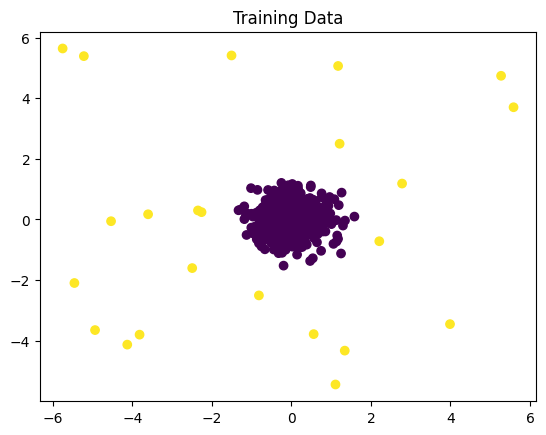

In [161]:
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train);
plt.title('Training Data');

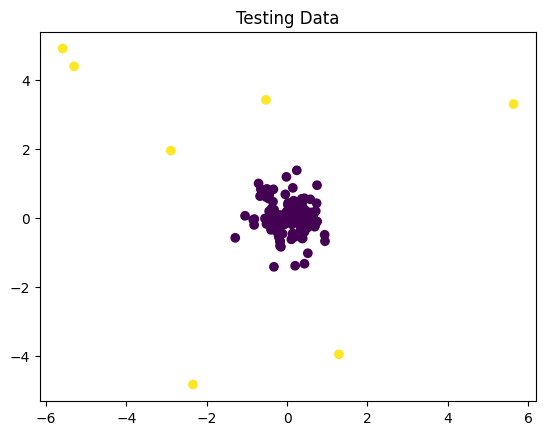

In [162]:
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test);
plt.title('Testing Data');

In [167]:
class GaussianAD:
    def __init__(self):
        self.mu = None
        self.sigma = None
        self.sigma_inv = None
        self.sigma_det = None
        self.n_features = None

    def fit(self, X):
        self.n_features = X.shape[1]
        # compute mean per feature
        self.mu = X.mean(axis=0)
        # compute covariance matrix
        self.sigma = np.cov(X, rowvar=False)
        # compute determinant and inverse to avoid repeated computations
        self.sigma_inv = np.linalg.inv(sigma)
        self.sigma_det = np.linalg.det(sigma)
        return self

    def predict(self, X, threshold=0.01):
        # calculate per-sample probabilities using the Multivariate Normal PDF
        probs = np.exp(-1/2 * np.sum((X - self.mu) @ self.sigma_inv * (X - self.mu), axis=1)) / ( (2 * np.pi)**(self.n_features/2) * np.sqrt(self.sigma_det) )
        return np.where(probs <= threshold, 1, 0)

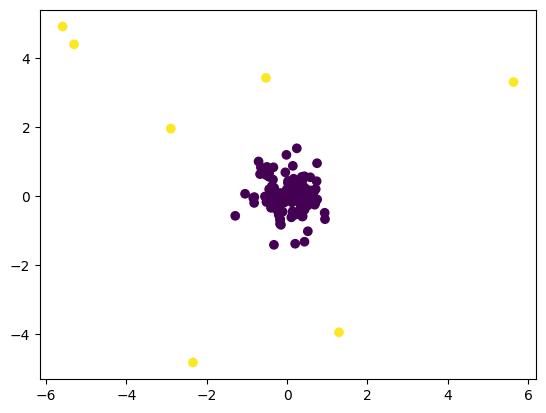

In [168]:
y_pred = GaussianAD().fit(X_train).predict(X_test)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_pred);